# Deteção de passes certos e falhados com MediaPipe + Bounding Boxes


---

## Objetivo
Detetar automaticamente, num lance de transmissão televisiva da Liga Portugal, **cada passe** e classificá-lo como:
- **certo:** a bola chega a um colega de equipa;
- **falhado:** a bola é intercetada ou fica com um adversário.

A partir daí tiram-se **indicadores táticos**: posse de bola, equipa mais próxima da bola, pressão sobre quem passa e taxa de sucesso dos passes.

## Porque os passes
Quase todos os eventos dependem do passe:
- o **fora de jogo** só se avalia **no instante do passe**. Sem saber quando há um passe, não há momento para verificar a linha;
- uma **falta** é, muitas vezes, uma perda de posse com contacto entre jogadores;
- um **penálti** é uma falta dentro da área.

Por isso, **saber quem tem a bola e quando ela muda de dono** é a base de tudo o resto.

## A ideia central
> **Não é preciso ver a bola durante o passe. Basta saber quem a tinha antes e quem a tem depois.**

A bola em voo é pequena, rápida e desfocada, e é a coisa mais difícil de detetar no vídeo (secção 4). Os jogadores, pelo contrário, são grandes e fáceis de seguir. Assim, em vez de seguirmos a bola no ar, olhamos para as **mudanças de dono**:

| Antes | Depois | Conclusão |
|---|---|---|
| Jogador A (equipa X) | Jogador B (equipa X) | **passe certo** |
| Jogador A (equipa X) | Jogador C (equipa Y) | **passe falhado** |

## Pipeline
| # | Etapa | Ferramenta | Porquê |
|---|---|---|---|
| 1 | Deteção de jogadores, GR, árbitros e bola | YOLOv8m (fine-tuning no Colab) | Modelo rápido e preciso para objetos em tempo real |
| 2 | Seguimento (IDs) | ByteTrack | Mantém o mesmo ID para o mesmo jogador ao longo do lance |
| 3 | Equipas | Cor do tronco em CIELAB + KMeans k=2 + voto por ID | Não precisa de treino: separa as camisolas pela cor |
| 4 | Pés | **MediaPipe Pose** (cascata) + **bounding box** | O contacto com a bola é feito com o pé |
| 5 | Bola | Seleção temporal + interpolação curta | Elimina bolas falsas e tapa pequenas falhas |
| 6 | Posse | Pé mais próximo da bola, à escala da altura do jogador | Normaliza a perspetiva da câmara |
| 7 | Equipa mais próxima e pressão | Distâncias jogador–bola e jogador–jogador | Sinal robusto quando a bola se perde |
| 8 | Passes | Transições de posse + regras | Classificação certo / falhado / disputa |
| 9 | Resultados | Indicadores, vídeo anotado, validação | Mostrar e medir o desempenho |

## 1. Configuração
Cada parâmetro abaixo tem uma razão concreta, que resulta dos testes feitos nos passos anteriores:

| Parâmetro | Valor | Porquê |
|---|---|---|
| `PASSO` | 2 | Os vídeos têm 50 fps. Analisar 1 frame em cada 2 (25 fps) chega para passes e corta o tempo para metade. |
| `CONF` | 0.2 | Confiança mínima do YOLO. Baixar mais não ajuda na bola rápida: abaixo de 0.1 só há ruído (secção 4). |
| `SALTO_MAX` | 150 px | A bola não "salta" mais de 150 px entre dois frames seguidos. Candidatos mais longe são falsos (chuteiras, linhas). |
| `N_PES` | 3 | O MediaPipe só corre nos 3 jogadores mais perto da bola, porque é caro e só esses podem ter a posse. |
| `MAX_BURACO` | 12 frames (≈0.5 s) | Só se interpolam falhas curtas da bola. Falhas longas são bola em voo e não se inventam posições. |
| `FATOR_DIST` | 0.6 alturas | Distância máxima pé–bola para haver posse. No lance Estrela Amadora–Sporting, o dono estava a 0.19–0.36 e o 2.º jogador a ≥ 1.09. |
| `MIN_POSSE` | 3 frames | Uma posse tem de durar pelo menos ~0.12 s, para eliminar jogadores que apenas passam perto da bola. |
| `MIN_VOO` | 0.2 s | Uma "mudança de dono" mais rápida do que isto entre adversários é uma **disputa** (duelo), não um passe. Caso real: 0.04 s no 3.º lance testado. |
| `MAX_VOO` | 3.0 s | Acima disto a receção não é observada com segurança e o resultado passa a ser **inferido**. |
| `RAIO_PRESSAO` | 2.0 alturas (≈3.5 m) | Adversários dentro deste raio estão a pressionar quem passa. |
| `ACHAT` | 0.4 | Na imagem de TV, a profundidade (eixo vertical) aparece comprimida. Uma distância vertical em píxeis vale ~2.5× mais no campo. |

In [75]:
%pip install -q "mediapipe==0.10.14" scikit-learn lap imageio-ffmpeg
from pathlib import Path
import tempfile, subprocess
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import mediapipe as mp, imageio_ffmpeg
from ultralytics import YOLO
from sklearn.cluster import KMeans
from tqdm.auto import tqdm
from IPython.display import Video, display

BASE = Path(r"C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS")
CAM_JOG = BASE / "treinos" / "players_ball_v1" / "weights" / "jogadores_best.pt"
PASTA_SAIDA = BASE / "resultados" / "passes"; PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

modelo = YOLO(str(CAM_JOG))
BOLA, GR, JOG, ARB = 0, 1, 2, 3
uncut = sorted((BASE / "videos" / "uncut").rglob("*.mp4"))   # 185 lances de ataque

# Parâmetros (ver tabela acima)
PASSO, CONF, SALTO_MAX, N_PES = 2, 0.2, 150, 3
MAX_BURACO, FATOR_DIST, MIN_POSSE = 12, 0.6, 3
MIN_VOO, MAX_VOO, DIST_TROCA_ID = 0.2, 3.0, 0.5
RAIO_PRESSAO, ACHAT, DIST_EQ_PROX, VEL_MIN = 2.0, 0.4, 1.5, 150

NOME_EQ = {0: "equipa clara", 1: "equipa escura"}
CORES = {0: (0, 0, 255), 1: (255, 0, 0), -1: (0, 255, 255)}   # BGR: clara = vermelho, escura = azul, outros = amarelo

print("Modelo:", modelo.names)
print(f"{len(uncut)} lances de ataque em videos/uncut")

Note: you may need to restart the kernel to use updated packages.
Modelo: {0: 'ball', 1: 'goalkeeper', 2: 'player', 3: 'referee'}
185 lances de ataque em videos/uncut



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Os pés dos jogadores: MediaPipe + bounding box


A posse de bola é um **contacto entre o pé e a bola**. A forma mais simples de saber onde estão os pés é usar a **base da bounding box** do YOLO (o centro do lado de baixo da caixa). Mas é só uma aproximação:
- quando o jogador corre, os pés estão afastados e a base da caixa fica **entre** os dois;
- quando o jogador estica a perna para chegar à bola, a caixa não acompanha bem.

O **MediaPipe Pose** estima 33 pontos do corpo, incluindo os **tornozelos (27, 28)** e as **pontas dos pés (31, 32)**. Com isso sabemos onde está exatamente cada pé.

### O problema e a solução
O MediaPipe foi treinado com pessoas grandes na imagem, e na transmissão os jogadores têm só **60–170 px de altura**. Por isso:
1. recorta-se o jogador com margem e **amplia-se o recorte** (256 px de altura) antes de correr o MediaPipe;
2. se falhar, tenta-se de novo com um recorte maior (384 px) e mais margem;
3. se ainda falhar, usa-se o modelo **heavy** (`model_complexity=2`), mais lento mas mais robusto;
4. se tudo falhar, usa-se a **base da bounding box**. Assim nunca ficamos sem um ponto de contacto.

### O que os testes mostraram (60 vídeos, frame do meio, jogador mais perto da bola)
| Estratégia | Pés detetados |
|---|---|
| MediaPipe numa só tentativa | 36 / 60 (60%) |
| **Cascata MediaPipe (256 → 384 → heavy)** | **46 / 60 (77%)** |
| Restantes com bounding box | 14 / 60 (23%) |

- As falhas **não dependem só do tamanho**: um jogador com 85 px funcionou e outro com 141 px falhou. Também contam a oclusão por outros jogadores, as costas viradas para a câmara e o desfoque de movimento.
- Num lance real (plano aberto, jogadores em duelo junto à bola), a bounding box foi usada em ~75% dos casos. É por isso que a combinação **MediaPipe + bounding box** é essencial: o MediaPipe dá precisão quando consegue e a caixa garante que temos sempre um ponto.

In [76]:
mp_pose = mp.solutions.pose
pose_rapida = mp_pose.Pose(static_image_mode=True, model_complexity=1, min_detection_confidence=0.3)
pose_forte  = mp_pose.Pose(static_image_mode=True, model_complexity=2, min_detection_confidence=0.2)
PES = {"tornozelo_esq": 27, "tornozelo_dir": 28, "pe_esq": 31, "pe_dir": 32}

TENTATIVAS = [("mediapipe_256",   pose_rapida, 0.15, 256),
              ("mediapipe_384",   pose_rapida, 0.30, 384),
              ("mediapipe_heavy", pose_forte,  0.30, 384)]

def correr_pose(frame, caixa, modelo_pose, margem, altura):
    # Recorta o jogador com margem, amplia o recorte e devolve os pés em coordenadas do frame.
    x1, y1, x2, y2 = caixa.astype(int)
    w, h = x2 - x1, y2 - y1
    x1m, y1m = max(0, x1 - int(margem * w)), max(0, y1 - int(margem * h))
    x2m, y2m = min(frame.shape[1], x2 + int(margem * w)), min(frame.shape[0], y2 + int(margem * h))
    crop = frame[y1m:y2m, x1m:x2m]
    if crop.size == 0:
        return None
    esc = altura / crop.shape[0]
    grande = cv2.resize(crop, None, fx=esc, fy=esc, interpolation=cv2.INTER_CUBIC)
    res = modelo_pose.process(cv2.cvtColor(grande, cv2.COLOR_BGR2RGB))
    if not res.pose_landmarks:
        return None
    lm = res.pose_landmarks.landmark
    gh, gw = grande.shape[:2]
    return {n: (x1m + lm[i].x * gw / esc, y1m + lm[i].y * gh / esc, lm[i].visibility) for n, i in PES.items()}

def pes_robusto(frame, caixa):
    # Cascata: MediaPipe 256 → 384 → heavy; se tudo falhar, base da bounding box.
    for nome, modelo_pose, margem, altura in TENTATIVAS:
        pes = correr_pose(frame, caixa, modelo_pose, margem, altura)
        if pes:
            return pes, nome
    x1, y1, x2, y2 = caixa
    return {"base_caixa": ((x1 + x2) / 2, y2, None)}, "bounding_box"

print("Cascata MediaPipe + bounding box pronta ✓")

Cascata MediaPipe + bounding box pronta ✓


## 3. Extração frame a frame

Para cada frame analisado guardamos **quem está em campo, onde está, de que equipa é e onde está a bola**. As decisões e o porquê de cada uma:

**Deteção + seguimento (YOLO + ByteTrack).** O ByteTrack dá a cada jogador um **ID persistente**. Usa também as deteções de baixa confiança para não perder o jogador quando fica parcialmente tapado. Cria-se um modelo novo por vídeo, para que os IDs de um lance não passem para o seguinte.

**Uma só bola por frame.** O modelo vê "bolas" falsas: chuteiras brancas, cruzamentos de linhas, o logótipo do canal. Como só existe uma bola, escolhe-se o candidato **mais próximo da posição anterior** (no máximo 150 px de salto). Ignoram-se as **zonas gráficas** (placar no canto superior esquerdo e logótipo no inferior direito). Se a bola se perder durante mais de 10 frames, recomeça-se pelo candidato de maior confiança.

**Equipas pela cor da camisola.**
- Usa-se só o **tronco** (20–45% da altura, 50% central da largura), porque calções e meias podem ter outra cor.
- **Remove-se a relva** com uma máscara HSV.
- A cor é medida em **CIELAB**, onde a distância entre cores corresponde à diferença que o olho vê, e o canal L separa equipamentos claros de escuros.
- **KMeans com k=2** no lance inteiro. O k=2 foi validado pelo método do cotovelo e pela silhueta (0.488 em CIELAB contra 0.308 com histogramas H×S).
- **Voto maioritário por ID:** se num frame a cor sai contaminada (sombra, outro jogador à frente), os restantes frames desse ID corrigem.

**Pés só dos 3 jogadores mais perto da bola.** O MediaPipe demora ~0.1–0.3 s por jogador e só quem está perto da bola pode ter a posse.

**Cache em CSV.** No PC (CPU) o YOLO processa ~0.4 frames/s, e um lance de 10 s demora ~10 min. Os resultados ficam guardados em `resultados/passes/<lance>_jogadores.csv` e `_bola.csv`, e da segunda vez lê-se o CSV em segundos. Para voltar a extrair, apaga-se o CSV.

In [77]:
def zona_grafica(x, y, W, H):
    return (x < 0.2 * W and y < 0.2 * H) or (x > 0.8 * W and y > 0.75 * H)

def cor_tronco(frame, caixa):
    x1, y1, x2, y2 = caixa.astype(int); w, h = x2 - x1, y2 - y1
    t = frame[y1 + int(.20 * h): y1 + int(.45 * h), x1 + int(.25 * w): x2 - int(.25 * w)]
    if t.size == 0:
        return None
    relva = cv2.inRange(cv2.cvtColor(t, cv2.COLOR_BGR2HSV), (35, 40, 40), (85, 255, 255)).reshape(-1)
    lab = cv2.cvtColor(t, cv2.COLOR_BGR2LAB).reshape(-1, 3)[relva == 0]
    return np.median(lab, axis=0) if len(lab) > 10 else None

def extrair_clip(video, max_seg=None, imgsz=1280):
    m = YOLO(str(CAM_JOG))                                   # modelo novo = tracker limpo
    cap = cv2.VideoCapture(str(video))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if max_seg:
        total = min(total, int(max_seg * fps))
    jog, bola, ultima, perdida = [], [], None, 0

    for idx in tqdm(range(total), desc=video.name):
        ok, frame = cap.read()
        if not ok:
            break
        if idx % PASSO:
            continue
        r = m.track(frame, persist=True, tracker="bytetrack.yaml", conf=CONF, imgsz=imgsz, verbose=False)[0]
        cx = r.boxes.xyxy.cpu().numpy(); cl = r.boxes.cls.cpu().numpy().astype(int); cf = r.boxes.conf.cpu().numpy()
        ids = r.boxes.id.cpu().numpy().astype(int) if r.boxes.id is not None else -np.ones(len(cl), int)

        # bola: 1 candidato por frame (continuidade temporal)
        cand = [((b[0] + b[2]) / 2, (b[1] + b[3]) / 2, c) for b, c in zip(cx[cl == BOLA], cf[cl == BOLA])]
        cand = [c for c in cand if not zona_grafica(c[0], c[1], W, H)]
        bc = None
        if cand:
            if ultima is None:
                bc = max(cand, key=lambda c: c[2])
            else:
                d = [np.hypot(c[0] - ultima[0], c[1] - ultima[1]) for c in cand]
                i = int(np.argmin(d))
                if d[i] <= SALTO_MAX * (1 + perdida):
                    bc = cand[i]
        if bc:
            ultima, perdida = bc[:2], 0
        else:
            perdida += 1
            if perdida > 10:
                ultima = None
        bola.append(dict(frame=idx, t=idx / fps, x=bc[0] if bc else np.nan,
                         y=bc[1] if bc else np.nan, conf=bc[2] if bc else np.nan))

        # pessoas (+ pés dos 3 mais perto da bola)
        pessoas = np.where(cl != BOLA)[0]
        perto = set()
        if bc:
            pj = [i for i in pessoas if cl[i] in (JOG, GR)]
            d = [np.hypot((cx[i, 0] + cx[i, 2]) / 2 - bc[0], cx[i, 3] - bc[1]) for i in pj]
            perto = {pj[k] for k in np.argsort(d)[:N_PES]}
        for i in pessoas:
            lin = dict(frame=idx, t=idx / fps, id=ids[i], cls=modelo.names[cl[i]], conf=cf[i],
                       x1=cx[i, 0], y1=cx[i, 1], x2=cx[i, 2], y2=cx[i, 3],
                       cor=cor_tronco(frame, cx[i]) if cl[i] == JOG else None,
                       pe_esq_x=np.nan, pe_esq_y=np.nan, pe_dir_x=np.nan, pe_dir_y=np.nan, metodo_pes=None)
            if i in perto:
                pes, met = pes_robusto(frame, cx[i])
                if met == "bounding_box":
                    bx, by, _ = pes["base_caixa"]
                    lin.update(pe_esq_x=bx, pe_esq_y=by, pe_dir_x=bx, pe_dir_y=by)
                else:
                    lin.update(pe_esq_x=pes["pe_esq"][0], pe_esq_y=pes["pe_esq"][1],
                               pe_dir_x=pes["pe_dir"][0], pe_dir_y=pes["pe_dir"][1])
                lin["metodo_pes"] = met
            jog.append(lin)
    cap.release()

    df_j, df_b = pd.DataFrame(jog), pd.DataFrame(bola)

    # equipas: KMeans k=2 no lance inteiro + voto maioritário por ID
    df_j["equipa"] = -1
    mask = df_j.cor.notna()
    if mask.sum() >= 2:
        X = np.stack(df_j.loc[mask, "cor"].values)
        km = KMeans(2, n_init=10, random_state=0).fit(X)
        escura = int(np.argmin(km.cluster_centers_[:, 0]))
        df_j.loc[mask, "equipa"] = (km.labels_ == escura).astype(int)
        com_id = mask & (df_j.id >= 0)
        voto = df_j[com_id].groupby("id").equipa.agg(lambda s: s.mode().iloc[0])
        df_j.loc[com_id, "equipa"] = df_j.loc[com_id, "id"].map(voto)
    return df_j.drop(columns="cor"), df_b, fps

def carregar_ou_extrair(video, max_seg=None):
    fj, fb = PASTA_SAIDA / f"{video.stem}_jogadores.csv", PASTA_SAIDA / f"{video.stem}_bola.csv"
    cap = cv2.VideoCapture(str(video)); fps = cap.get(cv2.CAP_PROP_FPS) or 25; cap.release()
    if fj.exists() and fb.exists():
        print(f"(cache) {video.name}: a ler os CSV já extraídos")
        return pd.read_csv(fj), pd.read_csv(fb), fps
    df_j, df_b, fps = extrair_clip(video, max_seg)
    df_j.to_csv(fj, index=False); df_b.to_csv(fb, index=False)
    return df_j, df_b, fps

print("Extração pronta ✓")

Extração pronta ✓


## 4. A bola: o elo mais fraco, e como o contornámos

### O que observámos
No lance Estrela Amadora–Sporting (8 s) a bola foi detetada em **34% dos frames**. A trajetória entre 0 e 3 s, com a bola nos pés do jogador, é **perfeita e contínua**. A bola desaparece **exatamente quando começa a andar depressa** (passe e remate de primeira).

### O que testámos para perceber porquê
| Teste | Resultado | Decisão |
|---|---|---|
| Baixar a confiança para 0.01 | Confiança máxima entre 0.00 e 0.10 na janela do passe: o modelo **não vê** a bola | ✗ Não é um problema de limiar |
| Resolução nativa (1920 em vez de 1280) | Não é consistentemente melhor e confunde chuteiras com bola. ~2× mais lento | ✗ Fica 1280 |
| Zoom por blocos (SAHI, 3×2 blocos) | Sobe a confiança, mas **também nas chuteiras e meias**. Os candidatos não estão na trajetória do remate | ✗ Descartado |

**Causa:** *domain gap*. O modelo foi treinado com um dataset público da Bundesliga (câmara tática), com poucas bolas desfocadas em movimento rápido. A solução definitiva é um **modelo de bola treinado nos vídeos da FootAR** 

### O que fazemos entretanto
1. **Interpolação só de buracos curtos** (≤ 0.5 s): uma falha de 2–3 frames com a bola nos pés é segura de preencher. Uma falha longa é bola em voo, e inventar posições aí geraria posses falsas.
2. **Não depender da bola em voo:** o passe deteta-se pela **mudança de dono** (secção 7).
3. Quando a bola não reaparece, usa-se a **equipa mais próxima** (secção 6).

In [78]:
def interpolar_bola(df_b):
    b = df_b.copy()
    if "interpolada" in b:                         # CSV antigo já interpolado: volta ao original
        b.loc[b.interpolada.astype(bool), ["x", "y"]] = np.nan
    nan = b.x.isna()
    grupo = (nan != nan.shift()).cumsum()
    tam = nan.groupby(grupo).transform("sum")
    cheio = b[["x", "y"]].interpolate(limit_area="inside")
    preencher = nan & (tam <= MAX_BURACO) & cheio.x.notna()
    b.loc[preencher, ["x", "y"]] = cheio.loc[preencher]
    b["interpolada"] = preencher
    return b

print("Interpolação pronta ✓")

Interpolação pronta ✓


## 5. Posse de bola


O dono da bola é o jogador **cujo pé está mais perto da bola**, desde que esteja perto o suficiente. O desafio é que, na imagem de TV, **um jogador ao fundo é muito mais pequeno do que um jogador à frente**. Uma distância de 40 px pode ser "colado à bola" ao fundo e "a 2 metros" à frente.

**Solução:** medir a distância **em alturas de jogador** (distância em píxeis ÷ altura da caixa). Assim o limiar funciona igual em todo o campo.
- Ponto do pé = pé esquerdo/direito do MediaPipe quando existe, senão a base da bounding box.
- Limiar `FATOR_DIST = 0.6`. Foi validado no lance Estrela Amadora–Sporting: o dono estava sempre a **0.19–0.36** e o segundo jogador mais próximo a **≥ 1.09**. A separação é clara.

### Segmentos de posse
Uma posse válida exige o **mesmo ID em pelo menos 3 frames**. Os frames sem dono pelo meio (bola tapada pelas pernas, por exemplo) são ignorados. Assim um jogador que só passa perto da bola não "rouba" a posse.

### Equipa mais próxima (calculada ao mesmo tempo)
Em cada frame guarda-se também a **distância do jogador mais próximo de cada equipa** à bola. Mesmo quando ninguém tem a posse (bola dividida, disputa), sabemos **que equipa está mais perto da bola**. É a base da secção 6.

In [79]:
def distancias_bola(p, bx, by):
    # Distância (em alturas de jogador) do pé mais próximo de cada jogador à bola.
    cxb = (p.x1 + p.x2) / 2
    d_esq = np.hypot(p.pe_esq_x.fillna(cxb) - bx, p.pe_esq_y.fillna(p.y2) - by)
    d_dir = np.hypot(p.pe_dir_x.fillna(cxb) - bx, p.pe_dir_y.fillna(p.y2) - by)
    return (np.minimum(d_esq, d_dir) / (p.y2 - p.y1)).values

def posse_por_frame(df_j, df_b):
    pj = df_j[df_j.cls.isin(["player", "goalkeeper"])]
    por_frame = {f: g for f, g in pj.groupby("frame")}
    linhas = []
    for b in df_b.itertuples():
        lin = dict(frame=b.frame, t=b.t, dono=-1, equipa=-1, dist_rel=np.nan,
                   d_eq0=np.nan, d_eq1=np.nan, eq_proxima=-1)
        p = por_frame.get(b.frame)
        if p is not None and pd.notna(b.x):
            rel = distancias_bola(p, b.x, b.y)
            k = int(np.argmin(rel))
            lin["dist_rel"] = rel[k]
            if rel[k] <= FATOR_DIST:
                lin["dono"], lin["equipa"] = int(p.id.iloc[k]), int(p.equipa.iloc[k])
            for e in (0, 1):
                m = p.equipa.values == e
                if m.any():
                    lin[f"d_eq{e}"] = rel[m].min()
            dd = [np.inf if np.isnan(lin["d_eq0"]) else lin["d_eq0"], np.inf if np.isnan(lin["d_eq1"]) else lin["d_eq1"]]
            if min(dd) < np.inf:
                lin["eq_proxima"] = int(np.argmin(dd))
        linhas.append(lin)
    return pd.DataFrame(linhas)

def segmentos_posse(df_p):
    cols = ["dono", "equipa", "t_ini", "t_fim", "frame_ini", "frame_fim", "n"]
    com = df_p[df_p.dono >= 0].copy()
    if com.empty:
        return pd.DataFrame(columns=cols)
    com["seg"] = (com.dono != com.dono.shift()).cumsum()
    seg = com.groupby("seg").agg(dono=("dono", "first"), equipa=("equipa", lambda s: s.mode().iloc[0]),
                                 t_ini=("t", "min"), t_fim=("t", "max"),
                                 frame_ini=("frame", "min"), frame_fim=("frame", "max"), n=("frame", "size"))
    seg = seg[seg.n >= MIN_POSSE].reset_index(drop=True)
    if seg.empty:
        return pd.DataFrame(columns=cols)
    # junta posses do mesmo jogador que ficaram separadas por um "toque falso" eliminado
    seg["g"] = (seg.dono != seg.dono.shift()).cumsum()
    seg = seg.groupby("g").agg(dono=("dono", "first"), equipa=("equipa", "first"), t_ini=("t_ini", "min"),
                               t_fim=("t_fim", "max"), frame_ini=("frame_ini", "min"),
                               frame_fim=("frame_fim", "max"), n=("n", "sum")).reset_index(drop=True)
    return seg[cols]

print("Posse pronta ✓")

Posse pronta ✓


## 6. Equipa mais próxima da bola e pressão


O jogador dono da bola é um sinal **frágil**: depende de a bola ser detetada e de o ID estar certo. Já a **equipa mais próxima da bola** é um sinal **robusto**: mesmo que a bola se perca ou que haja uma troca de ID, continua a ser fácil ver que equipa tem mais jogadores à volta da bola. Usamo-la de quatro formas:

1. **Controlo da bola:** a percentagem do tempo em que cada equipa é a mais próxima da bola. Comparada com a posse, diz-nos algo tático:
   - mais posse **e** mais vezes mais perto → controlo claro do lance;
   - **menos posse mas mais vezes mais perto** → a equipa está a **pressionar** quem tem a bola.
2. **Resolver passes em que a bola desaparece:** quando a bola se perde em voo e volta a aparecer, a equipa que está mais perto dela nesse momento (a menos de 1.5 alturas) é quem a ganhou.
3. **Direção da bola:** se a bola não reaparece, usamos a **direção em que ia** nos últimos frames. O primeiro jogador que está nessa linha (a menos de 1 altura de distância da linha) é o recetor provável, e a equipa dele decide o resultado.
4. **Pressão sobre quem passa:** conta-se quantos adversários estão a menos de **2 alturas (~3.5 m)** do passador no momento do passe. Hipótese a testar: **passes sob pressão falham mais**.

As inferências 2 e 3 são marcadas como **confiança baixa**, para separar o que foi **observado** do que foi **deduzido**.

**Nota sobre a perspetiva:** na imagem de TV, uma distância "para o fundo do campo" aparece encolhida (~2.5×). Por isso a distância vertical é dividida por `ACHAT = 0.4`, e a zona de pressão é uma **elipse** e não um círculo. Com a homografia (passo 5 do projeto) estas distâncias passarão a ser em metros reais.

In [80]:
def jogador_em(df_j, id_, frame):
    r = df_j[(df_j.id == id_) & (df_j.frame == frame)]
    return r.iloc[0] if len(r) else None

def ponto_pe(r):
    # Pé do MediaPipe se existir, senão base da bounding box.
    if pd.notna(r.pe_esq_x):
        return np.array([(r.pe_esq_x + r.pe_dir_x) / 2, max(r.pe_esq_y, r.pe_dir_y)])
    return np.array([(r.x1 + r.x2) / 2, r.y2])

def pressao(df_j, id_, frame, equipa):
    # N.º de adversários dentro da elipse de pressão à volta do jogador.
    r = jogador_em(df_j, id_, frame)
    if r is None or equipa not in (0, 1):
        return np.nan
    adv = df_j[(df_j.frame == frame) & (df_j.equipa == 1 - equipa) & (df_j.cls == "player")]
    if adv.empty:
        return 0
    pe, alt = ponto_pe(r), r.y2 - r.y1
    d = np.hypot((adv.x1 + adv.x2) / 2 - pe[0], (adv.y2 - pe[1]) / ACHAT) / alt
    return int((d <= RAIO_PRESSAO).sum())

def equipa_ao_reaparecer(df_p, df_bi, t_fim):
    # Depois de a bola se perder, que equipa está mais perto quando ela volta a aparecer?
    perdida = df_bi[(df_bi.t > t_fim) & df_bi.x.isna()]
    if perdida.empty:
        return None, None
    t0 = perdida.t.iloc[0]
    w = df_p[(df_p.t > t0) & (df_p.t <= t0 + MAX_VOO) & (df_p.eq_proxima >= 0)]
    dmin = np.fmin(w.d_eq0.fillna(np.inf), w.d_eq1.fillna(np.inf))
    w = w[dmin <= DIST_EQ_PROX]
    return (int(w.eq_proxima.iloc[0]), float(w.t.iloc[0])) if len(w) else (None, None)

def equipa_na_trajetoria(df_j, df_bi, t_fim, passador, janela=0.4):
    # Prolonga a direção da bola e devolve (equipa, id) do primeiro jogador nessa linha.
    pts = df_bi[(df_bi.t >= t_fim - janela) & (df_bi.t <= t_fim + janela) & df_bi.x.notna() & ~df_bi.interpolada]
    if len(pts) < 3:
        return None, None
    p0, p1 = pts[["x", "y"]].values[0], pts[["x", "y"]].values[-1]
    v = (p1 - p0) / max(pts.t.values[-1] - pts.t.values[0], 1e-6)
    if np.linalg.norm(v) < VEL_MIN:                      # bola parada / em condução: sem direção
        return None, None
    u = v / np.linalg.norm(v)
    fr = int(pts.frame.values[-1])
    cand = df_j[(df_j.frame == fr) & df_j.cls.isin(["player", "goalkeeper"]) & (df_j.id != passador)]
    melhor = None
    for r in cand.itertuples():
        w = np.array([(r.x1 + r.x2) / 2, r.y2]) - p1
        ao_longo = w @ u
        perp = abs(w[0] * u[1] - w[1] * u[0]) / (r.y2 - r.y1)
        if ao_longo > 0 and perp <= 1.0 and (melhor is None or ao_longo < melhor[0]):
            melhor = (ao_longo, int(r.id), int(r.equipa))
    return (melhor[2], melhor[1]) if melhor and melhor[2] >= 0 else (None, None)

print("Equipa mais próxima e pressão prontas ✓")

Equipa mais próxima e pressão prontas ✓


## 7. Deteção e classificação dos passes

### O que pensámos
Cada vez que a posse passa de um jogador A para um jogador B diferente, **pode** ser um passe. Mas há situações que parecem passes e não são. As regras abaixo foram construídas a partir dos **erros reais** que vimos nos lances testados:

| Situação | Classificação | Confiança | De onde veio a regra |
|---|---|---|---|
| A → B, mesma equipa, receção observada (≤ 3 s) | **certo** | alta | definição |
| A → B, equipas diferentes, receção observada | **falhado** | alta | definição |
| A → B adversários em **menos de 0.2 s** | **disputa** (não é passe) | - | 3.º lance: "passe" de 0.04 s, que era um duelo |
| A → B mesma equipa, < 0.3 s, caixas quase no mesmo sítio | **troca de ID** (ignorado) | - | o tracker às vezes dá um ID novo ao mesmo jogador |
| Bola perdida > 3 s antes de B | equipa mais próxima quando a bola reaparece | baixa | 3.º lance: falha de 3.24 s |
| Última posse e a bola não reaparece | equipa na **direção** da bola | baixa | Estrela Amadora–Sporting: passe + remate não observados |
| Guarda-redes ou equipa desconhecida | **indeterminado** | - | o GR tem equipamento próprio e não entra no KMeans |

Para cada passe guarda-se ainda:
- a **distância** passador → recetor (em alturas de jogador);
- a **pressão** sobre o passador (n.º de adversários na elipse).

In [81]:
COLS_PASSES = ["t_passe", "t_rececao", "voo_s", "passador", "eq_passador", "recetor", "eq_recetor",
               "distancia_alt", "pressao", "resultado", "confianca", "regra", "frame_passe", "frame_rececao"]

def detetar_passes(seg, df_j, df_bi, df_p):
    def base(a, b=None):
        d = dict(t_passe=round(a.t_fim, 2), frame_passe=int(a.frame_fim), passador=int(a.dono),
                 eq_passador=int(a.equipa), pressao=pressao(df_j, a.dono, a.frame_fim, a.equipa),
                 t_rececao=np.nan, frame_rececao=np.nan, recetor=np.nan, eq_recetor=np.nan,
                 voo_s=np.nan, distancia_alt=np.nan)
        if b is not None:
            d.update(t_rececao=round(b.t_ini, 2), frame_rececao=int(b.frame_ini), recetor=int(b.dono),
                     eq_recetor=int(b.equipa), voo_s=round(b.t_ini - a.t_fim, 2))
            ra, rb = jogador_em(df_j, a.dono, a.frame_fim), jogador_em(df_j, b.dono, b.frame_ini)
            if ra is not None and rb is not None:
                dd = ponto_pe(rb) - ponto_pe(ra)
                d["distancia_alt"] = round(float(np.hypot(dd[0], dd[1] / ACHAT) / (ra.y2 - ra.y1)), 1)
        return d

    ev, linhas = [], list(seg.itertuples())
    for a, b in zip(linhas[:-1], linhas[1:]):
        if a.dono == b.dono:
            continue
        d = base(a, b); voo = d["voo_s"]
        if a.equipa == b.equipa and voo < 0.3 and pd.notna(d["distancia_alt"]) and d["distancia_alt"] < DIST_TROCA_ID:
            continue                                                       # troca de ID
        if a.equipa != b.equipa and voo < MIN_VOO:
            d.update(resultado="disputa", confianca="-", regra="mudança de dono em < 0.2 s entre adversários")
        elif a.equipa < 0 or b.equipa < 0:
            d.update(resultado="indeterminado", confianca="-", regra="GR/árbitro ou equipa desconhecida")
        elif voo <= MAX_VOO:
            d.update(resultado="certo" if a.equipa == b.equipa else "falhado", confianca="alta",
                     regra="receção observada")
        else:
            eq, _ = equipa_ao_reaparecer(df_p, df_bi, a.t_fim)
            eq = b.equipa if eq is None else eq
            d.update(resultado="certo" if eq == a.equipa else "falhado", confianca="baixa",
                     regra=f"bola perdida {voo:.1f} s: equipa mais próxima ao reaparecer")
        ev.append(d)

    if linhas:                                                             # última posse do lance
        u = linhas[-1]
        if df_bi.t.max() - u.t_fim > 0.5:
            d = base(u)
            eq, _ = equipa_ao_reaparecer(df_p, df_bi, u.t_fim)
            regra = "equipa mais próxima quando a bola reaparece"
            if eq is None:
                eq, rid = equipa_na_trajetoria(df_j, df_bi, u.t_fim, u.dono)
                regra = f"equipa na direção da bola (ID {rid})"
            if eq is None or u.equipa < 0:
                d.update(resultado="indeterminado", confianca="-", regra="bola não reaparece e sem direção clara")
            else:
                d.update(resultado="certo" if eq == u.equipa else "falhado", confianca="baixa", regra=regra)
            ev.append(d)
    return pd.DataFrame(ev, columns=COLS_PASSES)

print("Deteção de passes pronta ✓")

Deteção de passes pronta ✓


## 8. Análise de um lance e conclusões automáticas

Juntamos tudo numa função `analisar_lance()`: extração (ou cache), depois interpolação, posse, segmentos e passes. A seguir, `conclusoes()` traduz os números em **frases**, porque é isso que interessa a um analista ou treinador:
- quem teve a posse e quem esteve mais perto da bola (e o que isso diz sobre pressão);
- quantos passes cada equipa fez e com que sucesso;
- se os passes sob pressão falham mais;
- quanto do resultado foi **observado** e quanto foi **inferido**;
- a qualidade dos dados (deteção da bola). Se for baixa, as conclusões são dadas com cautela.

Começamos pelo lance **Estrela Amadora–Sporting**, que já conhecemos: um jogador do Sporting conduz a bola ~3 s, passa a um colega e este remata de primeira para golo.

In [82]:
RESULTADOS = {}

def analisar_lance(video, max_seg=None):
    df_j, df_b, fps = carregar_ou_extrair(video, max_seg)
    df_bi = interpolar_bola(df_b)
    df_p = posse_por_frame(df_j, df_bi)
    seg = segmentos_posse(df_p)
    ps = detetar_passes(seg, df_j, df_bi, df_p)
    seg.to_csv(PASTA_SAIDA / f"{video.stem}_posse.csv", index=False)
    ps.to_csv(PASTA_SAIDA / f"{video.stem}_passes.csv", index=False)
    res = dict(video=video, fps=fps, df_j=df_j, df_bi=df_bi, df_p=df_p, seg=seg, passes=ps)
    RESULTADOS[video.stem] = res
    return res

def pct(a, b):
    return round(100 * a / b) if b else np.nan

def indicadores(res):
    p, ps, bi = res["df_p"], res["passes"], res["df_bi"]
    passes = ps[ps.resultado.isin(["certo", "falhado"])]
    com_dono, com_prox = p[p.equipa >= 0], p[p.eq_proxima >= 0]
    ind = dict(lance=res["video"].stem,
               bola_detetada_pct=pct((bi.x.notna() & ~bi.interpolada).sum(), len(bi)),
               bola_com_interp_pct=pct(bi.x.notna().sum(), len(bi)),
               passes=len(passes), certos=int((passes.resultado == "certo").sum()),
               falhados=int((passes.resultado == "falhado").sum()),
               confianca_alta=int((passes.confianca == "alta").sum()),
               disputas=int((ps.resultado == "disputa").sum()),
               indeterminados=int((ps.resultado == "indeterminado").sum()))
    for e in (0, 1):
        ind[f"posse_eq{e}_pct"] = pct((com_dono.equipa == e).sum(), len(com_dono))
        ind[f"proxima_eq{e}_pct"] = pct((com_prox.eq_proxima == e).sum(), len(com_prox))
        pe = passes[passes.eq_passador == e]
        ind[f"passes_eq{e}"] = len(pe)
        ind[f"sucesso_eq{e}_pct"] = pct((pe.resultado == "certo").sum(), len(pe))
    return ind

def conclusoes(res):
    ind, ps = indicadores(res), res["passes"]
    passes = ps[ps.resultado.isin(["certo", "falhado"])]
    print(f"══ Conclusões: {ind['lance']} ══\n")

    # 1. Qualidade dos dados
    q = ind["bola_detetada_pct"]
    print(f"• Qualidade: bola detetada em {q}% dos frames ({ind['bola_com_interp_pct']}% com interpolação)."
          + ("  ⚠ Abaixo de 50%: conclusões com cautela." if q < 50 else ""))

    # 2. Posse vs equipa mais próxima
    for e in (0, 1):
        print(f"• {NOME_EQ[e]}: {ind[f'posse_eq{e}_pct']}% da posse | mais próxima da bola em {ind[f'proxima_eq{e}_pct']}% do tempo")
    pos, prox = [ind["posse_eq0_pct"], ind["posse_eq1_pct"]], [ind["proxima_eq0_pct"], ind["proxima_eq1_pct"]]
    if not any(np.isnan(pos + prox)):
        dom_posse, dom_prox = int(np.argmax(pos)), int(np.argmax(prox))
        if dom_posse == dom_prox:
            print(f"  → A {NOME_EQ[dom_posse]} controlou o lance: mais posse e mais vezes perto da bola.")
        else:
            print(f"  → A {NOME_EQ[dom_prox]} teve menos posse mas esteve mais vezes perto da bola: "
                  f"sinal de pressão sobre a {NOME_EQ[dom_posse]}.")

    # 3. Passes
    if len(passes):
        print(f"• Passes: {len(passes)} ({ind['certos']} certos, {ind['falhados']} falhados), "
              f"{ind['confianca_alta']} observados e {len(passes) - ind['confianca_alta']} inferidos.")
        for e in (0, 1):
            if ind[f"passes_eq{e}"]:
                print(f"  - {NOME_EQ[e]}: {ind[f'passes_eq{e}']} passes, {ind[f'sucesso_eq{e}_pct']}% certos")
        sob = passes[passes.pressao >= 1]; livre = passes[passes.pressao == 0]
        if len(sob) and len(livre):
            print(f"• Pressão: sucesso {pct((sob.resultado == 'certo').sum(), len(sob))}% sob pressão ({len(sob)} passes) "
                  f"vs {pct((livre.resultado == 'certo').sum(), len(livre))}% sem pressão ({len(livre)} passes).")
        elif len(sob):
            print(f"• Pressão: todos os {len(sob)} passes foram feitos com pelo menos 1 adversário a ~3.5 m.")
    else:
        print("• Nenhum passe classificado neste lance.")
    if ind["disputas"]:
        print(f"• {ind['disputas']} disputa(s) de bola detetada(s) (mudança de dono em < 0.2 s), não contadas como passes.")
    if ind["indeterminados"]:
        print(f"• {ind['indeterminados']} evento(s) indeterminado(s) (GR envolvido ou bola não reaparece).")
    return ind

# Lance Estrela Amadora–Sporting
video = next(v for v in uncut if "EstrelaAmadora-Sporting_0-1" in v.name)
res = analisar_lance(video, max_seg=8)
print("Segmentos de posse:"); display(res["seg"])
print("Passes:"); display(res["passes"])
conclusoes(res);

(cache) J1-EstrelaAmadora-Sporting_0-1.mp4: a ler os CSV já extraídos
Segmentos de posse:


,dono,equipa,t_ini,t_fim,frame_ini,frame_fim,n
0,8,0,0.0,3.08,0,154,64


Passes:


,t_passe,t_rececao,voo_s,passador,eq_passador,recetor,eq_recetor,distancia_alt,pressao,resultado,confianca,regra,frame_passe,frame_rececao
0,3.08,NaN,NaN,8,0,NaN,NaN,NaN,2,certo,baixa,equipa mais próxima quando a bola reaparece,154,NaN


══ Conclusões: J1-EstrelaAmadora-Sporting_0-1 ══

• Qualidade: bola detetada em 34% dos frames (41% com interpolação).  ⚠ Abaixo de 50%: conclusões com cautela.
• equipa clara: 100% da posse | mais próxima da bola em 91% do tempo
• equipa escura: 0% da posse | mais próxima da bola em 9% do tempo
  → A equipa clara controlou o lance: mais posse e mais vezes perto da bola.
• Passes: 1 (1 certos, 0 falhados), 0 observados e 1 inferidos.
  - equipa clara: 1 passes, 100% certos
• Pressão: todos os 1 passes foram feitos com pelo menos 1 adversário a ~3.5 m.


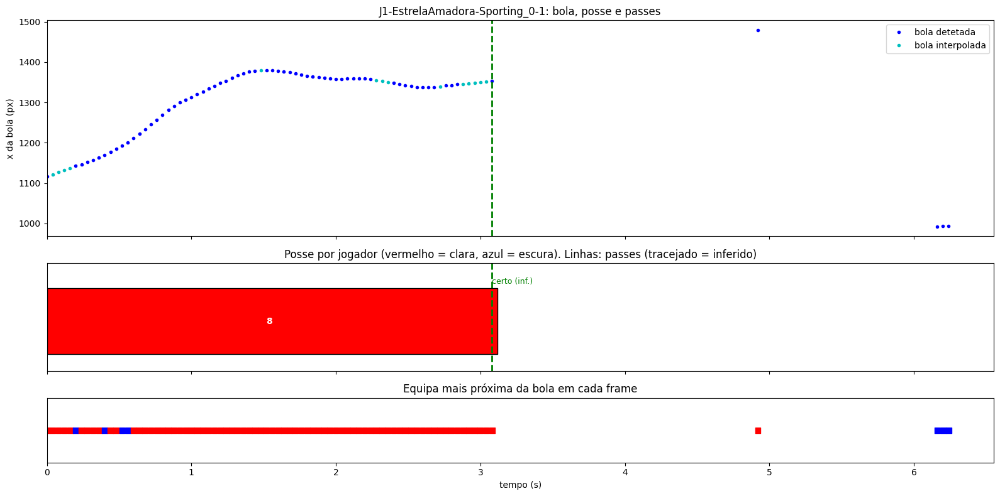

In [83]:
def grafico_lance(res):
    bi, p, seg, ps = res["df_bi"], res["df_p"], res["seg"], res["passes"]
    fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(16, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1, 0.6]})
    det, itp = bi[~bi.interpolada], bi[bi.interpolada]
    a1.plot(det.t, det.x, "b.", label="bola detetada"); a1.plot(itp.t, itp.x, "c.", label="bola interpolada")
    a1.set_ylabel("x da bola (px)"); a1.legend(loc="upper right"); a1.set_title(f"{res['video'].stem}: bola, posse e passes")
    COR = {0: "red", 1: "blue", -1: "gold"}
    for s in seg.itertuples():
        a2.barh(0, s.t_fim - s.t_ini + 0.04, left=s.t_ini, color=COR[s.equipa], edgecolor="k")
        a2.text((s.t_ini + s.t_fim) / 2, 0, str(int(s.dono)), ha="center", va="center", color="white", fontweight="bold")
    COR_RES = {"certo": "green", "falhado": "red", "disputa": "orange", "indeterminado": "gray"}
    for q in ps.itertuples():
        for ax in (a1, a2):
            ax.axvline(q.t_passe, color=COR_RES[q.resultado], ls="--" if q.confianca == "baixa" else "-", lw=2)
        a2.text(q.t_passe, 0.45, q.resultado + (" (inf.)" if q.confianca == "baixa" else ""),
                color=COR_RES[q.resultado], fontsize=9, rotation=0)
    a2.set_yticks([]); a2.set_ylim(-0.6, 0.7)
    a2.set_title("Posse por jogador (vermelho = clara, azul = escura). Linhas: passes (tracejado = inferido)")
    pp = p[p.eq_proxima >= 0]
    a3.scatter(pp.t, np.zeros(len(pp)), c=pp.eq_proxima.map({0: "red", 1: "blue"}), marker="s", s=40)
    a3.set_yticks([]); a3.set_xlabel("tempo (s)"); a3.set_title("Equipa mais próxima da bola em cada frame")
    plt.tight_layout(); plt.show()

grafico_lance(res)

### Lance Estrela Amadora–Sporting (o "primeiro impacto")
- **0–3.1 s:** a posse é atribuída a **um só jogador**, o ID 8 que conduz a bola, sem trocas de ID. Tracking, equipas e posse estão a funcionar.
- **~3.1 s:** o passe para o colega e o remate de primeira acontecem em **menos de 0.5 s**, com a bola rápida. A bola deixa de ser detetada e a receção **não é observada**.
- Mesmo assim, o sistema **acertou**. Quando a bola reaparece, a equipa mais próxima é a do passador, por isso classificou o passe como **certo**, com **confiança baixa** (inferido e não observado). Na validação (secção 11) este passe conta como acerto.
- A equipa clara (Sporting) teve **100% da posse** e esteve **mais perto da bola em 91% do tempo**: o lance foi controlado do início ao fim.
- No momento do passe havia **2 adversários a menos de ~3.5 m** do passador: um passe feito sob pressão.
- **Limitação conhecida:** o remate ainda não se distingue de um passe. Para isso é preciso saber a direção para a baliza, o que fica para um próximo passo com a homografia.

## 9. Vídeo anotado

### Porquê
Os números sozinhos não convencem. Uma pessoa da FootAR tem de **ver** o sistema a funcionar. O vídeo mostra, à velocidade real:
- caixas por equipa (vermelho = clara, azul = escura, verde = GR, amarelo = árbitro) com o ID;
- a bola e o seu rasto (branco = detetada, ciano = interpolada);
- o **dono da bola** com a caixa grossa e a **elipse de pressão** (~3.5 m) à volta, com o número de adversários lá dentro;
- os passes com uma seta passador → recetor e um aviso: **PASSE CERTO**, **PASSE FALHADO**, **DISPUTA** ou **INDETERMINADO** (com "inferido" quando a confiança é baixa);
- na barra de baixo: tempo, dono, **equipa mais próxima** e contagem de passes.

Não volta a correr o YOLO: usa as tabelas já calculadas, por isso demora menos de 1 minuto. É convertido para H.264 para tocar no VS Code.

In [84]:
def video_anotado(res, largura=1280):
    video, df_j, df_bi, df_p, ps = res["video"], res["df_j"], res["df_bi"], res["df_p"].set_index("frame"), res["passes"]
    cap = cv2.VideoCapture(str(video)); fps = cap.get(cv2.CAP_PROP_FPS)
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    h_out = int(H * largura / W) // 2 * 2
    tmp = Path(tempfile.gettempdir()) / "footar_tmp.mp4"
    out = cv2.VideoWriter(str(tmp), cv2.VideoWriter_fourcc(*"mp4v"), fps / PASSO, (largura, h_out))
    ev = ps.copy()
    ev["t_ev"] = ev.t_rececao.fillna(ev.t_passe).astype(float)
    COR_RES = {"certo": (0, 200, 0), "falhado": (0, 0, 255), "disputa": (0, 165, 255), "indeterminado": (160, 160, 160)}
    TXT_RES = {"certo": "PASSE CERTO", "falhado": "PASSE FALHADO", "disputa": "DISPUTA", "indeterminado": "INDETERMINADO"}
    por_frame = {f: g for f, g in df_j.groupby("frame")}
    rastro = []

    for idx in range(int(df_bi.frame.max()) + 1):
        ok, frame = cap.read()
        if not ok:
            break
        if idx % PASSO:
            continue
        t = idx / fps
        info = df_p.loc[idx] if idx in df_p.index else None
        dono = int(info.dono) if info is not None else -1
        eq_prox = int(info.eq_proxima) if info is not None else -1
        pj = por_frame.get(idx, df_j.iloc[0:0])

        for p in pj.itertuples():
            c = {"player": CORES.get(int(p.equipa), (0, 255, 255)), "goalkeeper": (0, 255, 0)}.get(p.cls, (0, 255, 255))
            grosso = p.id == dono
            cv2.rectangle(frame, (int(p.x1), int(p.y1)), (int(p.x2), int(p.y2)), c, 6 if grosso else 2)
            cv2.putText(frame, f"{p.id}" + (" POSSE" if grosso else ""), (int(p.x1), int(p.y1) - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9 if grosso else 0.6, c, 2)
            if pd.notna(p.pe_esq_x):
                for px, py in [(p.pe_esq_x, p.pe_esq_y), (p.pe_dir_x, p.pe_dir_y)]:
                    cv2.circle(frame, (int(px), int(py)), 5, (255, 0, 255), -1)
            if grosso:                                             # elipse de pressão
                pe, alt = ponto_pe(p), p.y2 - p.y1
                eixos = (int(RAIO_PRESSAO * alt), int(RAIO_PRESSAO * alt * ACHAT))
                cv2.ellipse(frame, (int(pe[0]), int(pe[1])), eixos, 0, 0, 360, c, 2)
                n = pressao(df_j, p.id, idx, int(p.equipa))
                if pd.notna(n):
                    cv2.putText(frame, f"pressao: {int(n)}", (int(pe[0]) + eixos[0] + 5, int(pe[1])),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.8, c, 2)

        b = df_bi[df_bi.frame == idx]
        if len(b) and pd.notna(b.x.iloc[0]):
            rastro.append((int(b.x.iloc[0]), int(b.y.iloc[0])))
            cv2.circle(frame, rastro[-1], 14, (255, 255, 0) if b.interpolada.iloc[0] else (255, 255, 255), 3)
        rastro = rastro[-15:]
        if len(rastro) > 1:
            cv2.polylines(frame, [np.array(rastro)], False, (255, 255, 255), 2)

        for q in ev[(ev.t_ev <= t) & (t <= ev.t_ev + 1.5)].itertuples():
            cor = COR_RES[q.resultado]
            ra = jogador_em(df_j, q.passador, q.frame_passe)
            rb = jogador_em(df_j, q.recetor, int(q.frame_rececao)) if pd.notna(q.frame_rececao) else None
            if ra is not None and rb is not None:
                cv2.arrowedLine(frame, tuple(ponto_pe(ra).astype(int)), tuple(ponto_pe(rb).astype(int)), cor, 5, tipLength=0.05)
            txt = TXT_RES[q.resultado] + (" (inferido)" if q.confianca == "baixa" else "")
            cv2.putText(frame, txt, (W // 2 - 330, 150), cv2.FONT_HERSHEY_SIMPLEX, 2.0, (0, 0, 0), 10)
            cv2.putText(frame, txt, (W // 2 - 330, 150), cv2.FONT_HERSHEY_SIMPLEX, 2.0, cor, 4)

        feitos = ev[ev.t_ev <= t]
        n_ok, n_f = (feitos.resultado == "certo").sum(), (feitos.resultado == "falhado").sum()
        prox_txt = NOME_EQ.get(eq_prox, "-")
        cv2.rectangle(frame, (0, H - 60), (W, H), (0, 0, 0), -1)
        cv2.putText(frame, f"t = {t:4.1f} s  |  dono: {dono if dono >= 0 else '-'}  |  mais perto da bola: {prox_txt}"
                           f"  |  passes certos: {n_ok}  falhados: {n_f}",
                    (30, H - 20), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
        out.write(cv2.resize(frame, (largura, h_out)))
    cap.release(); out.release()

    final = PASTA_SAIDA / f"{video.stem}_anotado.mp4"
    subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-i", str(tmp), "-c:v", "libx264",
                    "-pix_fmt", "yuv420p", "-preset", "veryfast", str(final)], capture_output=True)
    return final

final = video_anotado(res)
print("Guardado em:", final)
display(Video(str(final), embed=True, width=960))

Guardado em: C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS\resultados\passes\J1-EstrelaAmadora-Sporting_0-1_anotado.mp4


## 10. Vários lances

### Porquê
Um lance não prova nada. O sistema tem de funcionar em **estádios, equipamentos, ângulos e situações de jogo diferentes**. Corremos o mesmo pipeline, **sem mudar nenhum parâmetro**, em vários lances e comparamos os indicadores.

### Os lances escolhidos
| Lance | Porquê |
|---|---|
| **Estrela Amadora–Sporting** | **Primeiro impacto:** lance limpo (condução, passe e golo) em que se vê bem tudo a funcionar. |
| **Braga–Gil Vicente** | **Lance confuso:** posse dividida, disputas e passes certos e falhados. Mostra como o sistema se comporta quando o jogo é atabalhoado. |
| **Benfica–Académico** | Outra equipa, outro estádio, um lance de domínio de uma equipa. |
| **Outros** | Lances de jogos diferentes, para testar se o sistema generaliza. |

- Os lances já extraídos são lidos da cache (segundos).
- Os novos demoram ~10 min cada no PC (10 s de lance). Para os 185 lances, a extração deve ser feita no **Google Colab com GPU** (~1 h no total), copiando depois os CSV para `resultados/passes`.
- A célula mostra também a **lista de jogos disponíveis** em `uncut`, para escolher outros lances.

Lances a analisar: ['J1-EstrelaAmadora-Sporting_0-1', 'J2-Braga-GilVicente_1-0', 'J1-Benfica-Academico_1-0', 'J1-GilVicente-RioAve_1-0', 'J2-Sporting-VitoriaSC_1-0', 'J6-Benfica-GilVicente_0-1']

Jogos disponíveis em uncut (64), para trocar na lista ESCOLHA:
J1-Benfica-Academico, J1-Estoril-Famalicao, J1-EstrelaAmadora-Sporting, J1-FCPorto-Alverca, J1-GilVicente-RioAve, J1-Maritimo-CasaPia, J1-SantaClara-Nacional, J1-VitoriaSC-Arouca, J2-Academico-SantaClara, J2-Alverca-EstrelaAmadora, J2-Arouca-Moreirense, J2-Braga-GilVicente, J2-CasaPia-Benfica, J2-Famalicao-Maritimo, J2-Nacional-Estoril, J2-RioAve-FCPorto, J2-Sporting-VitoriaSC, J3-Estoril-RioAve, J3-EstrelaAmadora-Braga, J3-FCPorto-Arouca, J3-GilVicente-CasaPia, J3-Maritimo-Academico, J3-SantaClara-Famalicao, J3-Sporting-Alverca, J3-VitoriaSC-Nacional, J4-Academico-FCPorto, J4-Alverca-SantaClara, J4-Arouca-Maritimo, J4-Benfica-Estoril, J4-Braga-VitoriaSC, J4-CasaPia-Moreirense, J4-Nacional-EstrelaAmadora, J4-RioAve-Sporting, J5-Alv

J1-GilVicente-RioAve_1-0.mp4:   0%|          | 0/500 [00:00<?, ?it/s]

c:\Users\simao\anaconda3\envs\footar\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '



══ Conclusões: J1-GilVicente-RioAve_1-0 ══

• Qualidade: bola detetada em 25% dos frames (28% com interpolação).  ⚠ Abaixo de 50%: conclusões com cautela.
• equipa clara: 15% da posse | mais próxima da bola em 42% do tempo
• equipa escura: 85% da posse | mais próxima da bola em 58% do tempo
  → A equipa escura controlou o lance: mais posse e mais vezes perto da bola.
• Nenhum passe classificado neste lance.



J2-Sporting-VitoriaSC_1-0.mp4:   0%|          | 0/500 [00:00<?, ?it/s]

c:\Users\simao\anaconda3\envs\footar\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '



══ Conclusões: J2-Sporting-VitoriaSC_1-0 ══

• Qualidade: bola detetada em 42% dos frames (62% com interpolação).  ⚠ Abaixo de 50%: conclusões com cautela.
• equipa clara: 77% da posse | mais próxima da bola em 81% do tempo
• equipa escura: 23% da posse | mais próxima da bola em 19% do tempo
  → A equipa clara controlou o lance: mais posse e mais vezes perto da bola.
• Passes: 2 (0 certos, 2 falhados), 0 observados e 2 inferidos.
  - equipa clara: 1 passes, 0% certos
  - equipa escura: 1 passes, 0% certos
• Pressão: todos os 2 passes foram feitos com pelo menos 1 adversário a ~3.5 m.



J6-Benfica-GilVicente_0-1.mp4:   0%|          | 0/500 [00:00<?, ?it/s]

c:\Users\simao\anaconda3\envs\footar\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '



══ Conclusões: J6-Benfica-GilVicente_0-1 ══

• Qualidade: bola detetada em 33% dos frames (34% com interpolação).  ⚠ Abaixo de 50%: conclusões com cautela.
• equipa clara: 0% da posse | mais próxima da bola em 0% do tempo
• equipa escura: 100% da posse | mais próxima da bola em 100% do tempo
  → A equipa escura controlou o lance: mais posse e mais vezes perto da bola.
• Passes: 2 (2 certos, 0 falhados), 1 observados e 1 inferidos.
  - equipa escura: 2 passes, 100% certos
• Pressão: todos os 2 passes foram feitos com pelo menos 1 adversário a ~3.5 m.
• 1 evento(s) indeterminado(s) (GR envolvido ou bola não reaparece).



,bola_detetada_pct,passes,certos,falhados,confianca_alta,disputas,indeterminados,posse_eq0_pct,proxima_eq0_pct,posse_eq1_pct,proxima_eq1_pct
lance,,,,,,,,,,,
J1-EstrelaAmadora-Sporting_0-1,34,1,1,0,0,0,0,100,91,0,9
J2-Braga-GilVicente_1-0,25,4,2,2,3,1,1,48,39,52,61
J1-Benfica-Academico_1-0,31,1,1,0,0,0,0,89,66,11,34
J1-GilVicente-RioAve_1-0,25,0,0,0,0,0,0,15,42,85,58
J2-Sporting-VitoriaSC_1-0,42,2,0,2,0,0,0,77,81,23,19
J6-Benfica-GilVicente_0-1,33,2,2,0,1,0,1,0,0,100,100


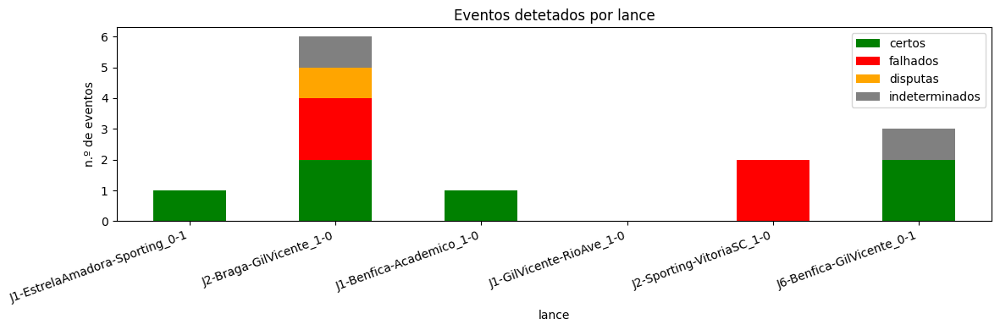

TOTAL: 10 passes classificados | 60% certos | 40% observados (confiança alta) | 1 disputas | 2 indeterminados | bola detetada em média 32% dos frames


In [85]:
import re

# ⬇️ lances a analisar (parte do nome). O 1.º é o de "primeiro impacto".
ESCOLHA = ["EstrelaAmadora-Sporting_0-1",   # limpo: condução + passe + golo
           "Braga-GilVicente_1-0",          # confuso: disputas, passes certos e falhados
           "Benfica-Academico_1-0",         # domínio de uma equipa
            "J1-GilVicente-RioAve_1-0",      # outros jogos (para testar se generaliza)
           "J2-Sporting-VitoriaSC_1-0",
           "J6-Benfica-GilVicente_0-1"]
EXCLUIR = ["FCPorto-Alverca"]
N_LANCES, MAX_SEG = 6, 10

lances = []
for k in ESCOLHA:
    v = next((v for v in uncut if k.lower() in v.name.lower()
              and not any(e.lower() in v.name.lower() for e in EXCLUIR)), None)
    if v is None:
        print(f"⚠ Não encontrei nenhum lance com '{k}' em uncut")
    elif v not in lances:
        lances.append(v)
lances = lances[:N_LANCES]
print("Lances a analisar:", [v.stem for v in lances])

jogos = sorted({re.sub(r"_\d+-\d+.*$", "", v.stem) for v in uncut})
print(f"\nJogos disponíveis em uncut ({len(jogos)}), para trocar na lista ESCOLHA:")
print(", ".join(jogos), "\n")

linhas = []
for v in lances:
    r = analisar_lance(v, max_seg=MAX_SEG)
    print(); ind = conclusoes(r); print()
    linhas.append(ind)

tabela = pd.DataFrame(linhas).set_index("lance")
display(tabela[["bola_detetada_pct", "passes", "certos", "falhados", "confianca_alta", "disputas", "indeterminados",
                "posse_eq0_pct", "proxima_eq0_pct", "posse_eq1_pct", "proxima_eq1_pct"]])

ax = tabela[["certos", "falhados", "disputas", "indeterminados"]].plot.bar(
    stacked=True, figsize=(12, 4), color=["green", "red", "orange", "gray"])
ax.set_ylabel("n.º de eventos"); ax.set_title("Eventos detetados por lance"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

tot = tabela[["passes", "certos", "falhados", "confianca_alta", "disputas", "indeterminados"]].sum()
print(f"TOTAL: {tot.passes} passes classificados | {pct(tot.certos, tot.passes)}% certos | "
      f"{pct(tot.confianca_alta, tot.passes)}% observados (confiança alta) | {tot.disputas} disputas | "
      f"{tot.indeterminados} indeterminados | bola detetada em média {tabela.bola_detetada_pct.mean():.0f}% dos frames")

In [86]:
# Vídeos anotados de todos os lances analisados
for v in lances:
    f = video_anotado(RESULTADOS[v.stem])
    print(v.name, "→", f.name)
    display(Video(str(f), embed=True, width=960))

J1-EstrelaAmadora-Sporting_0-1.mp4 → J1-EstrelaAmadora-Sporting_0-1_anotado.mp4


J2-Braga-GilVicente_1-0.mp4 → J2-Braga-GilVicente_1-0_anotado.mp4


J1-Benfica-Academico_1-0.mp4 → J1-Benfica-Academico_1-0_anotado.mp4


J1-GilVicente-RioAve_1-0.mp4 → J1-GilVicente-RioAve_1-0_anotado.mp4


J2-Sporting-VitoriaSC_1-0.mp4 → J2-Sporting-VitoriaSC_1-0_anotado.mp4


J6-Benfica-GilVicente_0-1.mp4 → J6-Benfica-GilVicente_0-1_anotado.mp4


### Como ler os vários lances
**Braga–Gil Vicente, o lance confuso:**
- **Posse quase dividida** (48% clara / 52% escura) e a equipa escura mais perto da bola em 61% do tempo: um lance disputado, sem dono claro.
- **4 passes, 3 deles observados** (confiança alta): 2 certos e 2 falhados. A equipa escura fez 3 passes com 67% de sucesso e a equipa clara perdeu o único passe que fez.
- **Todos os passes foram feitos sob pressão** (pelo menos 1 adversário a ~3.5 m), o que é coerente com um lance atabalhoado.
- **1 disputa** (mudança de dono em menos de 0.2 s) foi corretamente **excluída** dos passes. Sem esta regra teria sido contada como um passe falhado.
- **1 evento indeterminado**: o sistema prefere dizer "não sei" a inventar.

É um bom exemplo de que o sistema **não colapsa num lance confuso**. Separa passes, disputas e casos sem informação suficiente.

**Benfica–Académico:** a equipa clara teve **89% da posse** mas só esteve mais perto da bola em **66% do tempo**. Tinha a bola, mas o adversário estava frequentemente perto: pressão sem conseguir recuperar.

**Restantes lances:** acrescentar aqui a leitura depois de correr (pontos fortes, erros e qualidade da deteção da bola).

## 11. Validação com o que acontece no vídeo (ground truth)

### Porquê

- um passe detetado a **menos de 1 s** de um passe anotado conta como **acerto (VP)**;
- um passe detetado sem correspondência é um **falso positivo (FP)**;
- um passe anotado que o sistema não viu é um **falso negativo (FN)**;




In [87]:
GROUND_TRUTH = {
    # lance: [(tempo_aproximado_s, "certo" ou "falhado"), ...]
    "J1-EstrelaAmadora-Sporting_0-1": [(3.0, "certo")],    # passe para o colega, que remata de primeira (golo)
    # "J2-Braga-GilVicente_1-0": [(1.5, "certo"), (4.0, "falhado")],   # <- preencher depois de ver o vídeo
}
TOL = 1.0

def avaliar(res, gt):
    det = res["passes"][res["passes"].resultado.isin(["certo", "falhado"])].copy()
    usados, vp, cls_ok = set(), 0, 0
    for t_gt, r_gt in gt:
        cand = det[~det.index.isin(usados)]
        if cand.empty:
            continue
        i = (cand.t_passe - t_gt).abs().idxmin()
        if abs(det.loc[i, "t_passe"] - t_gt) <= TOL:
            usados.add(i); vp += 1; cls_ok += int(det.loc[i, "resultado"] == r_gt)
    fp, fn = len(det) - vp, len(gt) - vp
    return dict(VP=vp, FP=fp, FN=fn, classificacao_ok=cls_ok)

linhas = []
for nome, gt in GROUND_TRUTH.items():
    if nome not in RESULTADOS:
        print("Lance ainda não analisado:", nome); continue
    linhas.append(dict(lance=nome, passes_reais=len(gt), **avaliar(RESULTADOS[nome], gt)))

aval = pd.DataFrame(linhas)
if len(aval):
    s = aval[["VP", "FP", "FN", "classificacao_ok"]].sum()
    display(aval)
    print(f"Precisão: {pct(s.VP, s.VP + s.FP)}% | Recall: {pct(s.VP, s.VP + s.FN)}% | "
          f"Acerto na classificação (certo/falhado): {pct(s.classificacao_ok, s.VP)}%")

,lance,passes_reais,VP,FP,FN,classificacao_ok
0,J1-EstrelaAmadora-Sporting_0-1,1,1,0,0,1


Precisão: 100% | Recall: 100% | Acerto na classificação (certo/falhado): 100%


## 12. Conclusões 

### O que funciona
- **Seguimento dos jogadores (YOLO + ByteTrack):** estável durante a condução de bola (o mesmo ID durante 3 s no lance Estrela Amadora–Sporting).
- **Equipas sem treino adicional:** CIELAB + KMeans k=2 + voto por ID separa as camisolas (silhueta 0.488).
- **Pés com MediaPipe + bounding box:** a cascata MediaPipe chega a 77% dos jogadores perto da bola e a bounding box cobre o resto. Há sempre um ponto de contacto.
- **Posse de bola:** o critério em alturas de jogador separa claramente o dono (0.19–0.36) do segundo mais próximo (≥ 1.09).
- **Regras construídas a partir de erros reais:** disputas (< 0.2 s), trocas de ID e bola perdida deixam de gerar passes falsos.
- **Equipa mais próxima:** dá um sinal robusto mesmo sem bola, que usamos para deduzir o resultado de passes não observados e para medir pressão.

### Limitações
- **Bola rápida:** é o principal ponto fraco (34% de deteção no lance analisado). Testámos limiar baixo, resolução nativa e zoom por blocos, e nenhum resolve. **Precisa de um modelo de bola treinado nos vídeos da FootAR.**
- **Remate vs passe:** ainda não se distinguem.
- **Guarda-redes:** sem equipa atribuída. Os passes que envolvem o GR ficam indeterminados.
- **Distâncias em alturas de jogador:** são aproximadas. A homografia dará metros reais.
- **Tempo de processamento no PC (CPU):** ~10 min por lance de 10 s. A análise dos 185 lances deve ser feita no Colab com GPU.

### Próximos passos
1. Obter o **modelo de bola da**(ou anotar frames de bola rápida no Roboflow da FootAR) e repetir a avaliação.
2. Preencher o **ground truth** em pelo menos 10–15 lances para ter precisão e recall com significado.
3. Correr os **185 lances no Colab** e produzir estatísticas por equipa.
4. Usar o **instante do passe** para avaliar o **fora de jogo** com a homografia (já implementada no passo 5).
5. Distinguir **remates** (bola em direção à baliza) e avançar para **faltas e penáltis**.